문제) titanic폴더에 있는 train.csv 파일을 사용하여 딥러닝으로 모델링하는 코드를 작성하시오.

제출형식 : 1112_홍길동_정확도.ipynb
제출기한 : 11월 13일 오전 9시까지
발표시간 : 최소 5분에서 최대 10분

<처리조건>
1. 타이타닉 데이터에 대한 분석을 한다.
2. 분석한 결과를 토대로 데이터 전처리를 수행한다.
3. 최종적으로 모델링한 결과를 보여준다.
4. 마지막에 테스트 데이터에 대한 정확도를 출력한다.
5. 학습 데이터와 테스트 데이터는 8:2로 한다.
6. 타겟은 Survived이다.

In [1]:
import pandas as pd
import numpy as np
from sklearn.metrics import accuracy_score

df = pd.read_csv('titanic/train.csv')
df.head(10)
#SibSp -> 함께 탄 형제자매 + 배우자 
#Parch -> 부모, 자녀 (위아래 세대)
#Cabin: 객실 번호
#Embarked: 탑승 항구
#고유값추정 : 	PassengerId,Name,Ticket	

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C


In [2]:
print(df['PassengerId'].nunique())
print("================")
print(df['Name'].nunique())
print("================")
print(df['Ticket'].nunique())
#고유값인지 알아보려고 찍음. 
#몇 종류인지 (NaN 제외)

891
891
681


In [3]:
df.shape

(891, 12)

In [4]:
print(df.isnull().sum()) #컬럼별 결측치개수
print("=====================")
print(df.duplicated().sum()) #중복행갯수

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64
0


In [5]:
print(df.describe())
#숫자만 나와서 cabin이나 embarked는 안보임 
#확인해봐야할것 
#Fare 최고요금 512인데 75%는 31이라 확인필요-> 최고요금 512는 타이타닉의 최고급 객실요금
#fare의 min에서 0도있음 -> 선박회사 직원이나 초대받은 승객처럼 무료로 탄 사람이라고함 ->오류 x
#age의 최소 0.4 -> 0.4세의 아기 이상치아님 
#분포 (mean vs 50%) 차이가 큰 컬럼 sibsp,Fare,Parch

       PassengerId    Survived      Pclass         Age       SibSp  \
count   891.000000  891.000000  891.000000  714.000000  891.000000   
mean    446.000000    0.383838    2.308642   29.699118    0.523008   
std     257.353842    0.486592    0.836071   14.526497    1.102743   
min       1.000000    0.000000    1.000000    0.420000    0.000000   
25%     223.500000    0.000000    2.000000   20.125000    0.000000   
50%     446.000000    0.000000    3.000000   28.000000    0.000000   
75%     668.500000    1.000000    3.000000   38.000000    1.000000   
max     891.000000    1.000000    3.000000   80.000000    8.000000   

            Parch        Fare  
count  891.000000  891.000000  
mean     0.381594   32.204208  
std      0.806057   49.693429  
min      0.000000    0.000000  
25%      0.000000    7.910400  
50%      0.000000   14.454200  
75%      0.000000   31.000000  
max      6.000000  512.329200  


In [6]:
print(df['SibSp'].value_counts().head(10))
print("==========================")
print(df['Fare'].value_counts().head(10))
print("==========================")
print(df['Parch'].value_counts().head(10))
#mean과 중앙값의 차이가 큰 이유를 확인하려고 찍어 본 것

SibSp
0    608
1    209
2     28
4     18
3     16
8      7
5      5
Name: count, dtype: int64
Fare
8.0500     43
13.0000    42
7.8958     38
7.7500     34
26.0000    31
10.5000    24
7.9250     18
7.7750     16
26.5500    15
7.2292     15
Name: count, dtype: int64
Parch
0    678
1    118
2     80
5      5
3      5
4      4
6      1
Name: count, dtype: int64


In [7]:
#결측치있는 Age,Cabin,Embarked 
print(df['Age'].value_counts().head(10))
print("==========================")
print(df['Cabin'].value_counts().head(10))
print("==========================")
print(df['Embarked'].value_counts().head(10))

#범주형인지 수치형인지 알아야할것같아서 찍어봤음. 
#범주형이라면 ->최빈값
#수치형 -> 왜도계산 
#age 
#Cabin은 결측치가 많고 값도 다 제각각임 -> 지우는 쪽으로
#Embarked는 최빈값으로 채우기로결정

Age
24.0    30
22.0    27
18.0    26
28.0    25
19.0    25
30.0    25
21.0    24
25.0    23
36.0    22
29.0    20
Name: count, dtype: int64
Cabin
G6             4
C23 C25 C27    4
B96 B98        4
F33            3
E101           3
F2             3
D              3
C22 C26        3
C123           2
D33            2
Name: count, dtype: int64
Embarked
S    644
C    168
Q     77
Name: count, dtype: int64


In [8]:
#수치형 왜도계산 0.5이상이면 중앙값사용추천 
#왜도가 작아도 극단적인 이상치가 몇 개 있으면 중앙값이 더 안전합니다.
#왜도가 낮으면 평균값과 중앙값이 비슷함


In [9]:
#age의 왜도계산을 하는 김에 로그변환때 필요한값들을 미리 계산 시켜주고싶어서 전체컬럼의 왜도구함 
#빼기로한 컬럼제외 Cabin,PassengerId,Name,Ticket
#Survived는 타깃(0/1), Pclass는 등급(1·2·3)이라 로그 변환 대상이 아니므로 제외	
#Sex와 Embarked는 문자열이라 제외 
skew_cols = ['Age', 'SibSp', 'Parch', 'Fare']
skew = df[skew_cols].skew().sort_values(ascending=False)
print(skew)


Fare     4.787317
SibSp    3.695352
Parch    2.749117
Age      0.389108
dtype: float64


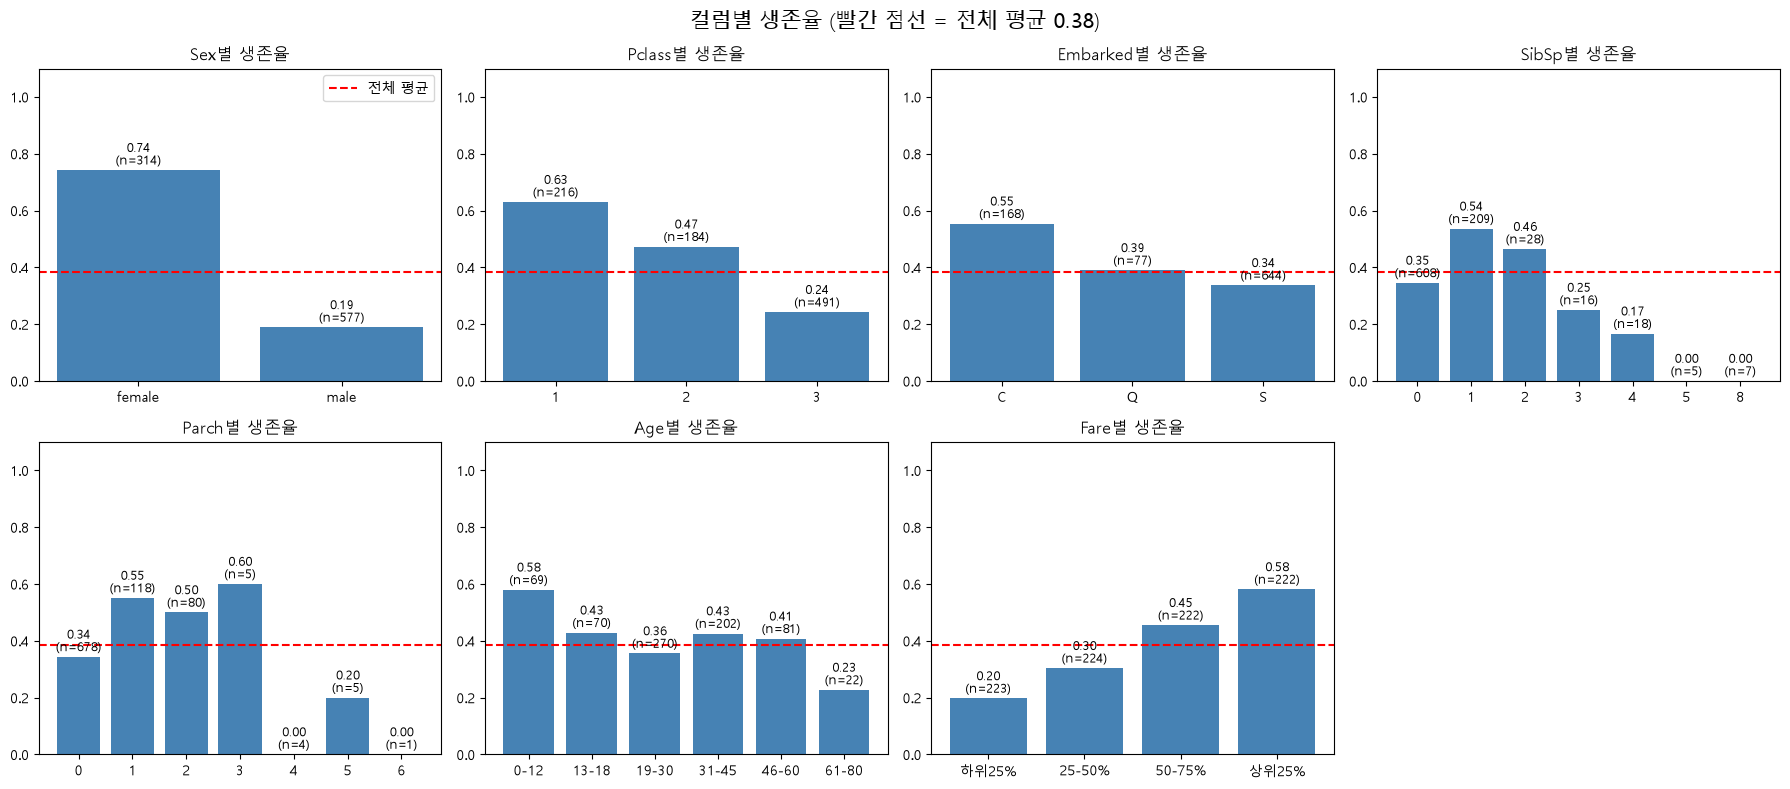

In [10]:
#생존율을 컬럼별로 비교하기 위한 셀
#값 종류가 적은 컬럼(성별, 객실 등급, 탑승 항구, 형제·배우자 수, 부모·자녀 수)은 값별로 그대로 생존율을 구함

import matplotlib.pyplot as plt

plt.rcParams['font.family'] = 'Malgun Gothic'   # 한글 깨짐 방지
plt.rcParams['axes.unicode_minus'] = False

# 연속형(Age, Fare)은 구간으로 나눠서 범주처럼 봄
age_bin = pd.cut(df['Age'], bins=[0, 12, 18, 30, 45, 60, 80],
                 labels=['0-12', '13-18', '19-30', '31-45', '46-60', '61-80'])
# pd.cut: 연속형 Age를 나이 구간으로 나눠 범주처럼 만듦
# Age가 NaN인 행은 구간 없이 NaN으로 남음 → groupby가 NaN을 기본으로 제외해서 그래프는 714명 기준

fare_bin = pd.qcut(df['Fare'], 4, labels=['하위25%', '25-50%', '50-75%', '상위25%'])
#pd.qcut을 써서 인원이 같도록 4등분
# Fare는 왜도가 4.79로 많이 치우쳐 있어서, 같은 간격으로 나누면 거의 모든 사람이 첫 구간에 사람들이 몰려있음


groups = {
    'Sex': df['Sex'],
    'Pclass': df['Pclass'],
    'Embarked': df['Embarked'],
    'SibSp': df['SibSp'],
    'Parch': df['Parch'],
    'Age': age_bin,
    'Fare': fare_bin,
}

mean_rate = df['Survived'].mean()   # 전체 평균 생존율 (약 0.38)

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.ravel()

for ax, (name, col) in zip(axes, groups.items()):
    rate = df.groupby(col, observed=False)['Survived'].mean()   # 값별 생존율
    count = df.groupby(col, observed=False)['Survived'].count() # 값별 인원수

    ax.bar(rate.index.astype(str), rate.values, color='steelblue')
    ax.axhline(mean_rate, color='red', linestyle='--', label='전체 평균')
    ax.set_title(f'{name}별 생존율')
    ax.set_ylim(0, 1.1)

    # 막대 위에 생존율과 인원수 표시
    for i, (r, n) in enumerate(zip(rate.values, count.values)):
        ax.text(i, r + 0.02, f'{r:.2f}\n(n={n})', ha='center', fontsize=9)

axes[0].legend()
axes[-1].axis('off')   # 8번째 빈 칸 숨김

plt.suptitle('컬럼별 생존율 (빨간 점선 = 전체 평균 0.38)', fontsize=15)
plt.tight_layout()
plt.show()

#막대가 빨간 점선에서 멀수록 그 컬럼이 생존 예측에 중요
#n이 작으면 우연일수있으므로 신뢰성이 낮음 sibsp의 n=5나 , parch의 n=1
#의미있는것 성별, Pclass , age가 어릴수록 생존확률높음 
#요금,pclass는 높을수록 생존확률 높음
#EMbark도 유의미한수치를 보이는데 무슨의미인지 모르겠음.

In [11]:
# 분석 결과 사용하지 않기로 한 컬럼 삭제
# PassengerId, Name, Ticket: 거의 고유값 → 예측에 의미 없음
# Name은 새로운 전처리때 다시씀. 중요한 컬럼이었음
# Cabin: 결측치 77% / 나머지도 거의 고유값 → 삭제
df = df.drop(columns=['PassengerId', 'Name', 'Ticket', 'Cabin'])
print(df.columns)

Index(['Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare',
       'Embarked'],
      dtype='str')


In [12]:
#결측치 채우기 전에 train과 test나눔 
#데이터 누수방지 
#중앙값 평균으로 채우기 전에 나눠야함  

from sklearn.model_selection import train_test_split

# 입력(X)과 타깃(y) 분리
X = df.drop(columns=['Survived'])
y = df['Survived']

# 학습 8 : 테스트 2
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,      # 테스트 20%
    random_state=42,    # 실행할 때마다 같은 결과가 나오도록 고정
    stratify=y          # train과 test의 생존 비율(약 38%)을 똑같이 유지
)

print(X_train.shape, X_test.shape)    # (712, n) (179, n)
print(y_train.mean(), y_test.mean())  # 둘 다 약 0.38

(712, 7) (179, 7)
0.38342696629213485 0.3854748603351955


In [13]:
X_train = X_train.copy()
X_test = X_test.copy()

# Age: 왜도 0.39 (< 0.5) → 거의 대칭이라 평균으로 채움
age_mean = X_train['Age'].mean()
X_train['Age'] = X_train['Age'].fillna(age_mean)
X_test['Age'] = X_test['Age'].fillna(age_mean)

# Embarked: 범주형 → 최빈값으로 채움
emb_mode = X_train['Embarked'].mode()[0]
X_train['Embarked'] = X_train['Embarked'].fillna(emb_mode)
X_test['Embarked'] = X_test['Embarked'].fillna(emb_mode)

print("Age 평균:", age_mean, "/ Embarked 최빈값:", emb_mode)
print("===== X_train 결측치 =====")
print(X_train.isnull().sum())
print("===== X_test 결측치 =====")
print(X_test.isnull().sum())

Age 평균: 29.807686956521735 / Embarked 최빈값: S
===== X_train 결측치 =====
Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    0
dtype: int64
===== X_test 결측치 =====
Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    0
dtype: int64


In [14]:
# Sex: 값이 2개 → 0/1로 변환
X_train['Sex'] = X_train['Sex'].map({'male': 0, 'female': 1})
X_test['Sex'] = X_test['Sex'].map({'male': 0, 'female': 1})

# Embarked: 순서 없는 범주 → 원-핫 인코딩
X_train = pd.get_dummies(X_train, columns=['Embarked'], dtype=int)
X_test = pd.get_dummies(X_test, columns=['Embarked'], dtype=int)
#모델은 숫자만 계산 Embarked는  크고 작은 순서가 없음
# 그런데 숫자 0, 1, 2를 넣으면 모델은 "Q(2)는 S(0)의 2배"처럼 계산할수있으므로 원핫인코딩

# test에 없는 범주가 있어도 train과 컬럼을 똑같이 맞춤
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

print(X_train.head())
print(X_train.columns.equals(X_test.columns))   # True면 성공

     Pclass  Sex        Age  SibSp  Parch      Fare  Embarked_C  Embarked_Q  \
692       3    0  29.807687      0      0   56.4958           0           0   
481       2    0  29.807687      0      0    0.0000           0           0   
527       1    0  29.807687      0      0  221.7792           0           0   
855       3    1  18.000000      0      1    9.3500           0           0   
801       2    1  31.000000      1      1   26.2500           0           0   

     Embarked_S  
692           1  
481           1  
527           1  
855           1  
801           1  
True


In [15]:
# 왜도 1 이상(많이 치우침) → 로그 변환: Fare(4.79), SibSp(3.70), Parch(2.75)
# log1p = log(1+x) → 0이 있어도 계산 가능 (Fare 0원, SibSp/Parch 0명)
# 각 행만 변환해서 데이터 누수 없음
log_cols = ['Fare', 'SibSp', 'Parch']

print("변환 전 왜도\n", X_train[log_cols].skew())

X_train[log_cols] = np.log1p(X_train[log_cols])
X_test[log_cols] = np.log1p(X_test[log_cols])

print("변환 후 왜도\n", X_train[log_cols].skew())

#SibSp, Parch는 0이 많아서 효과가 제한적이었다

변환 전 왜도
 Fare     4.646190
SibSp    3.815617
Parch    2.842562
dtype: float64
변환 후 왜도
 Fare     0.312461
SibSp    1.715546
Parch    1.716580
dtype: float64


In [16]:
from sklearn.preprocessing import StandardScaler

# 컬럼마다 범위가 달라서 스케일링
# (Age 0~80, Fare 로그 후 0~6 등)
# Sex(map으로 0/1 변환)와 Embarked_(원-핫)는 이미 0/1이라 스케일링에서 제외
# 데이터 누수 방지: train으로만 fit, test는 transform만
binary_cols = ['Sex'] + [c for c in X_train.columns if c.startswith('Embarked_')]
scale_cols = [c for c in X_train.columns if c not in binary_cols]

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

scaler = StandardScaler()
X_train_scaled[scale_cols] = scaler.fit_transform(X_train[scale_cols])
X_test_scaled[scale_cols] = scaler.transform(X_test[scale_cols])


In [17]:
# MLP(다층퍼셉트론) 1층 512 -> 2층 512 /  1층 32 -> 2층 32 

In [18]:
#모델설계 
import tensorflow as tf
tf.get_logger().setLevel('ERROR')
from tensorflow import keras
from keras.models import Sequential
from keras.layers import Dense, Dropout, Activation
from keras.callbacks import EarlyStopping

keras.utils.set_random_seed(42)

X_tr = X_train_scaled.values.astype('float32')
X_te = X_test_scaled.values.astype('float32')
y_tr = y_train.values.astype('float32')
y_te = y_test.values.astype('float32')

model = Sequential()
model.add(Dense(512, input_shape=(X_tr.shape[1],)))   
model.add(Activation("relu"))
model.add(Dropout(0.2))
model.add(Dense(512))                                 
model.add(Activation("relu"))
model.add(Dropout(0.2))
model.add(Dense(1))
#이진분류라 1
model.add(Activation("sigmoid"))
#이진분류라 sigmoid
model.summary()

model.compile(loss="binary_crossentropy",
              optimizer="adam",
              metrics=["accuracy"])


early = EarlyStopping(monitor='val_loss', patience=20, restore_best_weights=True)
#EarlyStopping(...)	조기 종료 규칙을 만드는 Keras 콜백. 매 에폭이 끝날 때마다 호출돼서 계속할지 멈출지 판단함
#monitor='val_loss'	지켜볼 지표는 검증 데이터의 loss. 학습 loss는 계속 내려가기만 해서 과적합을 못 잡기 때문에 검증 쪽을 봄
#patience=20	최저 기록이 20에폭 연속으로 갱신되지 않으면 멈춤. 한두 에폭 잠깐 나빠지는 것은 봐주려는 여유분
#restore_best_weights=True	멈출 때 가중치를 val_loss가 가장 낮았던 에폭의 것으로 되돌림. 없으면 마지막 에폭(과적합된 상태)의 가중치가 남음

hist = model.fit(X_tr, y_tr,
                 validation_split=0.2,
                 epochs=200, batch_size=32,
                 callbacks=[early])

print("학습한 에폭 수:", len(hist.history['loss']))


print("가중치를 가져온 에폭:", early.best_epoch + 1)
print("그때의 val_loss:", early.best)

#train의 569 ÷ 배치사이즈 32 = 17.8 

c:\Users\leegi\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\layers\core\dense.py:100: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 512)            │         5,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 512)            │       262,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │           513 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 1)              │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 268,289 (1.02 MB)

 Trainable params: 268,289 (1.02 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step - accuracy: 0.7241 - loss: 0.5442 - val_accuracy: 0.7692 - val_loss: 0.4918
Epoch 2/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7996 - loss: 0.4384 - val_accuracy: 0.8392 - val_loss: 0.4398
Epoch 3/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8278 - loss: 0.4069 - val_accuracy: 0.8112 - val_loss: 0.4474
Epoch 4/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8366 - loss: 0.4018 - val_accuracy: 0.8042 - val_loss: 0.4500
Epoch 5/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8453 - loss: 0.3829 - val_accuracy: 0.8112 - val_loss: 0.4593
Epoch 6/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8489 - loss: 0.3748 - val_accuracy: 0.8112 - val_loss: 0.4710
Epoch 7/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8594 - loss: 0.3665 - val_accuracy: 0.8112 - val_loss: 0.4760
Epoch 8/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8471 - loss: 0.3623 - val_accuracy: 0.8112 - 

In [19]:
score = model.evaluate(X_te, y_te, verbose=1)
print("\n loss=", score[0])
print("accuracy", score[1])



6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7765 - loss: 0.4713 

 loss= 0.4713003635406494
accuracy 0.7765362858772278


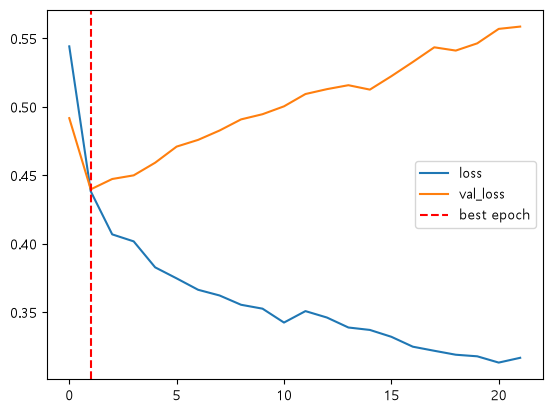

In [20]:
plt.plot(hist.history["loss"], label="loss")
plt.plot(hist.history["val_loss"], label="val_loss")
plt.axvline(early.best_epoch, color="red", linestyle="--", label="best epoch")
plt.legend()
plt.show()

In [21]:
#모델설계 
import tensorflow as tf
tf.get_logger().setLevel('ERROR')
from tensorflow import keras
from keras.models import Sequential
from keras.layers import Dense, Dropout, Activation
from keras.callbacks import EarlyStopping

keras.utils.set_random_seed(42)

X_tr = X_train_scaled.values.astype('float32')
X_te = X_test_scaled.values.astype('float32')
y_tr = y_train.values.astype('float32')
y_te = y_test.values.astype('float32')

model = Sequential()
model.add(Dense(32, input_shape=(X_tr.shape[1],)))   # 512 → 32
model.add(Activation("relu"))
model.add(Dropout(0.2))
model.add(Dense(32))                                 # 512 → 32
model.add(Activation("relu"))
model.add(Dropout(0.2))
model.add(Dense(1))
#이진분류라 1
model.add(Activation("sigmoid"))
#이진분류라 sigmoid
model.summary()

model.compile(loss="binary_crossentropy",
              optimizer="adam",
              metrics=["accuracy"])

early = EarlyStopping(monitor='val_loss', patience=20, restore_best_weights=True)

hist = model.fit(X_tr, y_tr,
                 validation_split=0.2,
                 epochs=200, batch_size=32,
                 callbacks=[early])

print("학습한 에폭 수:", len(hist.history['loss']))
print("가중치를 가져온 에폭:", early.best_epoch + 1)
print("그때의 val_loss:", early.best)
#train의 569 ÷ 배치사이즈 32 = 17.8 


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 32)             │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            33 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 1)              │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,409 (5.50 KB)

 Trainable params: 1,409 (5.50 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step - accuracy: 0.5764 - loss: 0.6850 - val_accuracy: 0.5804 - val_loss: 0.6531
Epoch 2/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.6292 - loss: 0.6236 - val_accuracy: 0.6713 - val_loss: 0.6177
Epoch 3/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7030 - loss: 0.5823 - val_accuracy: 0.7413 - val_loss: 0.5919
Epoch 4/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.7065 - loss: 0.5703 - val_accuracy: 0.7413 - val_loss: 0.5702
Epoch 5/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7241 - loss: 0.5486 - val_accuracy: 0.7203 - val_loss: 0.5523
Epoch 6/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7557 - loss: 0.5169 - val_accuracy: 0.7343 - val_loss: 0.5365
Epoch 7/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7575 - loss: 0.5142 - val_accuracy: 0.7273 - val_loss: 0.5211
Epoch 8/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7627 - loss: 0.5034 - val_accuracy: 0.7552 -

In [22]:
score = model.evaluate(X_te, y_te, verbose=1)
print("\n loss=", score[0])
print("accuracy", score[1])

6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7709 - loss: 0.4679 

 loss= 0.46793001890182495
accuracy 0.7709497213363647


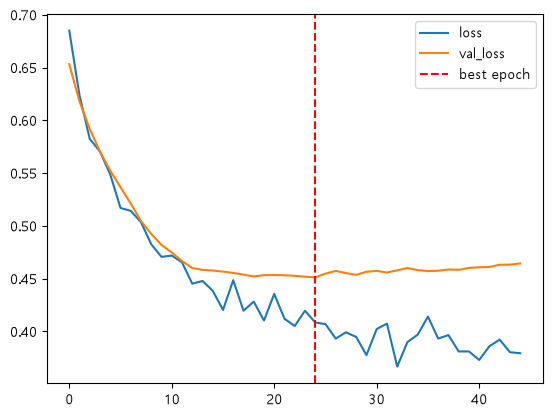

In [23]:
plt.plot(hist.history["loss"], label="loss")
plt.plot(hist.history["val_loss"], label="val_loss")
plt.axvline(early.best_epoch, color="red", linestyle="--", label="best epoch")
plt.legend()
plt.show()

In [24]:
#성능이비슷하면 단순한쪽을 고르는게 원칙 32->32 

In [25]:
# # 모델 크기를 바꿔도(512→512, 32→32) 테스트 정확도가 77%대에서 오르지 않음
# 모델이 아니라 입력 데이터(전처리)를 개선하기로 함
# 앞에서 버렸던 Name 컬럼에서 호칭(Mr, Miss, Mrs, Master)을 뽑아서
#   1) 나이 결측치를 호칭별 평균으로 채우고
#   2) 호칭 자체도 원-핫 인코딩해서 입력으로 사용
# SibSp와 Parch를 FamilySize로 합침
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 데이터를 새로 불러옴 (위에서 Name을 이미 지웠기 때문)
df = pd.read_csv('titanic/train.csv')
df.head(10)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C


In [26]:
#  Name에서 호칭 추출: "Braund, Mr. Owen Harris" → "Mr"
#    쉼표 뒤부터 마침표 앞까지의 글자를 꺼냄
title = df['Name'].str.extract(r',\s*([^\.]+)\.')[0].str.strip()
# 같은 뜻의 호칭은 하나로 합침 (Mlle·Ms = Miss, Mme = Mrs)
title = title.replace({'Mlle': 'Miss', 'Ms': 'Miss', 'Mme': 'Mrs'})
# 4개 주요 호칭 외(Dr, Rev, Col 등)는 인원이 적어서 Rare로 묶음
df['Title'] = title.where(title.isin(['Mr', 'Miss', 'Mrs', 'Master']), 'Rare')
# Mr 성인 남성 / Miss 미혼 여성 (어린 여자아이 포함) / Mrs 기혼 여성 / Master 남자아이 (당시 소년에게 쓰던 호칭)
# 코드에서 만든 묶음. Dr(의사), Rev(목사), Col·Major(군인), Lady·Sir(귀족) 같은 호칭은 나이를 나타내지도않을뿐더러 각각 1~7명뿐이라 원핫인코딩에부적합 
# Mlle, Ms는 Miss에, Mme는 Mrs에 합쳤음. Mlle ,Mme 프랑스식 표기일 뿐 뜻이 같음
# 의미있는 이유: 남녀로만 나눠진것과는 다르게 남자아이와 성인남성의 분류를 나눔
print(df['Title'].value_counts())

# SibSp(형제·배우자)와 Parch(부모·자녀)를 합쳐 가족 수 컬럼을 만듦 
df['FamilySize'] = df['SibSp'] + df['Parch'] 

#  사용하지 않는 컬럼 삭제 (호칭을 뽑았으니 Name은 삭제)
df = df.drop(columns=['PassengerId', 'Name', 'Ticket', 'Cabin'])
# FamilySize로 합쳤으니 SibSp, Parch 원본은 삭제
df = df.drop(columns=['SibSp', 'Parch'])
# 동반 가족 수별 생존율 (train으로만 계산)


Title
Mr        517
Miss      185
Mrs       126
Master     40
Rare       23
Name: count, dtype: int64


In [27]:



# 결측치를 채우기 전에 train/test 분리 (데이터 누수 방지)
X = df.drop(columns=['Survived'])
y = df['Survived']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
X_train = X_train.copy()
X_test = X_test.copy()



In [ ]:
# 호칭별 생존율은 분할 뒤에 train으로만 계산 (test의 정답을 미리 보지 않기 위해)
print("===== 호칭별 생존율(train) =====")
print(y_train.groupby(X_train['Title']).mean())

# Age 결측치: train의 호칭별 평균 나이로 채움
# (기존: 모두 29.8세 → 변경: Master 4세, Miss 22세, Mr 32세, Mrs 36세)
# 호칭별 평균도 train으로만 계산해서 test에 그대로 적용
age_mean = X_train['Age'].mean()
title_age = X_train.groupby('Title')['Age'].mean()
print("===== 호칭별 평균 나이(train) =====")
print(title_age)
X_train['Age'] = X_train['Age'].fillna(X_train['Title'].map(title_age)).fillna(age_mean)
X_test['Age'] = X_test['Age'].fillna(X_test['Title'].map(title_age)).fillna(age_mean)

# Embarked 결측치: 최빈값으로 채움
emb_mode = X_train['Embarked'].mode()[0]
X_train['Embarked'] = X_train['Embarked'].fillna(emb_mode)
X_test['Embarked'] = X_test['Embarked'].fillna(emb_mode)

# 인코딩: Sex는 0/1, Embarked와 Title은 순서 없는 범주라 원-핫
X_train['Sex'] = X_train['Sex'].map({'male': 0, 'female': 1})
X_test['Sex'] = X_test['Sex'].map({'male': 0, 'female': 1})
X_train = pd.get_dummies(X_train, columns=['Embarked', 'Title'], dtype=int)
X_test = pd.get_dummies(X_test, columns=['Embarked', 'Title'], dtype=int)
# test에 없는 범주가 있어도 train과 컬럼을 똑같이 맞춤
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

# 동반 가족 수별 생존율 (train으로만 계산)
print("===== 동반 가족 수별 생존율 =====")
print(y_train.groupby(X_train['FamilySize']).agg(['mean', 'count']))

===== 호칭별 생존율(train) =====
Title
Master    0.548387
Miss      0.708333
Mr        0.152913
Mrs       0.785047
Rare      0.388889
Name: Survived, dtype: float64
===== 호칭별 평균 나이(train) =====
Title
Master     4.238214
Miss      21.552966
Mr        32.400943
Mrs       36.074468
Rare      46.058824
Name: Age, dtype: float64
===== 동반 가족 수별 생존율 =====
                mean  count
FamilySize                 
0           0.299539    434
1           0.550388    129
2           0.623377     77
3           0.727273     22
4           0.214286     14
5           0.062500     16
6           0.363636     11
7           0.000000      4
10          0.000000      5


In [29]:
#로그 변환: 왜도 1 이상인 Fare, FamilySize
log_cols = ['Fare', 'FamilySize']

print("왜도\n", X_train[log_cols].skew())

왜도
 Fare          4.646190
FamilySize    2.718601
dtype: float64


In [30]:

# 로그 변환: 왜도 1 이상인 Fare, FamilySize
log_cols = ['Fare', 'FamilySize']
X_train[log_cols] = np.log1p(X_train[log_cols])
X_test[log_cols] = np.log1p(X_test[log_cols])
print("변환 후 왜도\n", X_train[log_cols].skew())

#  스케일링: 0/1 컬럼(Sex, Embarked_, Title_)은 제외, train으로만 fit
binary_cols = ['Sex'] + [c for c in X_train.columns if c.startswith(('Embarked_', 'Title_'))]
scale_cols = [c for c in X_train.columns if c not in binary_cols]
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()
scaler = StandardScaler()
X_train_scaled[scale_cols] = scaler.fit_transform(X_train[scale_cols])
X_test_scaled[scale_cols] = scaler.transform(X_test[scale_cols])

print("===== 결측치 =====")
print(X_train_scaled.isnull().sum().sum(), X_test_scaled.isnull().sum().sum())   # 둘 다 0이면 성공
print("입력 컬럼 수:", X_train_scaled.shape[1])   # 기존 9개 → 13개
print(list(X_train_scaled.columns))

변환 후 왜도
 Fare          0.312461
FamilySize    1.209731
dtype: float64
===== 결측치 =====
0 0
입력 컬럼 수: 13
['Pclass', 'Sex', 'Age', 'Fare', 'FamilySize', 'Embarked_C', 'Embarked_Q', 'Embarked_S', 'Title_Master', 'Title_Miss', 'Title_Mr', 'Title_Mrs', 'Title_Rare']


In [31]:
import tensorflow as tf
tf.get_logger().setLevel('ERROR')
from tensorflow import keras
from keras.models import Sequential
from keras.layers import Dense, Dropout, Activation
from keras.callbacks import EarlyStopping

keras.utils.set_random_seed(42)

X_tr = X_train_scaled.values.astype('float32')
X_te = X_test_scaled.values.astype('float32')
y_tr = y_train.values.astype('float32')
y_te = y_test.values.astype('float32')

# 모델 구조와 학습 설정은 앞의 32→32와 완전히 동일 
model = Sequential()
model.add(Dense(32, input_shape=(X_tr.shape[1],)))
model.add(Activation("relu"))
model.add(Dropout(0.2))
model.add(Dense(32))
model.add(Activation("relu"))
model.add(Dropout(0.2))
model.add(Dense(1))
model.add(Activation("sigmoid"))
model.summary()

model.compile(loss="binary_crossentropy",
              optimizer="adam",
              metrics=["accuracy"])

early = EarlyStopping(monitor='val_loss', patience=20, restore_best_weights=True)

hist = model.fit(X_tr, y_tr,
                 validation_split=0.2,
                 epochs=200, batch_size=32,
                 callbacks=[early])

print("학습한 에폭 수:", len(hist.history['loss']))
print("가중치를 가져온 에폭:", early.best_epoch + 1)
print("그때의 val_loss:", early.best)

c:\Users\leegi\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\layers\core\dense.py:100: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 32)             │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_6 (Activation)       │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_7 (Activation)       │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 1)              │            33 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_8 (Activation)       │ (None, 1)              │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,537 (6.00 KB)

 Trainable params: 1,537 (6.00 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 39ms/step - accuracy: 0.6362 - loss: 0.6584 - val_accuracy: 0.7203 - val_loss: 0.6346
Epoch 2/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7223 - loss: 0.5919 - val_accuracy: 0.7622 - val_loss: 0.5780
Epoch 3/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7698 - loss: 0.5422 - val_accuracy: 0.7483 - val_loss: 0.5335
Epoch 4/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7487 - loss: 0.5127 - val_accuracy: 0.7483 - val_loss: 0.5020
Epoch 5/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7891 - loss: 0.4970 - val_accuracy: 0.8042 - val_loss: 0.4815
Epoch 6/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8032 - loss: 0.4540 - val_accuracy: 0.7902 - val_loss: 0.4665
Epoch 7/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8102 - loss: 0.4658 - val_accuracy: 0.8182 - val_loss: 0.4552
Epoch 8/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8102 - loss: 0.4510 - val_accuracy: 0.8182 - 

In [32]:
score = model.evaluate(X_te, y_te, verbose=1)
print("\n loss=", score[0])
print("accuracy", score[1])

6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8156 - loss: 0.4420 

 loss= 0.4419621229171753
accuracy 0.8156424760818481


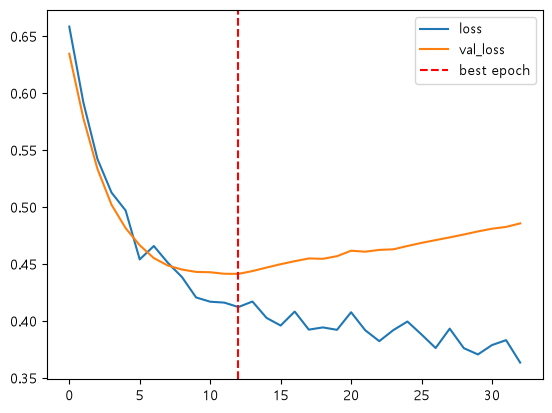

In [33]:
plt.plot(hist.history["loss"], label="loss")
plt.plot(hist.history["val_loss"], label="val_loss")
plt.axvline(early.best_epoch, color="red", linestyle="--", label="best epoch")
plt.legend()
plt.show()